In [2]:
source("~/AllFunctions/aging_functions.R")
library(dplyr)
library(plotly)
library(Seurat)
library(biomaRt)
library(pheatmap)
library(circlize)
library(ggridges)
library(htmlwidgets)

#### Convert raw counts to TPM

In [4]:
raw_to_tpm <- function(obj){
    # 1. Extract raw counts
    counts <- GetAssayData(obj, slot = "counts")

    # 2. Get gene lengths (in base pairs)
    # For example using biomaRt
    mart <- useEnsembl(biomart = "genes", dataset = "mmusculus_gene_ensembl")
    gene_info <- getBM(attributes = c("external_gene_name", "start_position", "end_position"),
                       filters = "external_gene_name",
                       values = rownames(counts),
                       mart = mart)
    gene_info$length <- gene_info$end_position - gene_info$start_position + 1
    lengths <- setNames(gene_info$length, gene_info$external_gene_name)

    # Match to counts
    common_genes <- intersect(rownames(counts), names(lengths))
    counts <- counts[common_genes, ]
    lengths <- lengths[common_genes]

    # 3. Calculate TPM
    tpm <- apply(counts, 2, function(col) {
      rpk <- col / (lengths / 1000)
      rpk / sum(rpk) * 1e6})
    
    return(tpm)}

makeSeuratObject <- function(obj){
    counts <- as.data.frame(obj$raw$X)
    rownames(counts) <- rownames(obj$obs)
    colnames(counts) <- colnames(obj)
    obj <- CreateSeuratObject(counts = t(counts),
                                             metadata = obj$obs)
    return(obj)}

#### CSOmap functions

In [34]:
########################################################################################################################

run_CSOmap <- function(max_iter){
#     coords <- CSOmap()
    library(CSOmapR)
    affinityMat = getAffinityMat(TPM, LR, verbose = T)
    coords_res = runExactTSNE_R(
      X = affinityMat,
      no_dims = 3,
      max_iter = max_iter,
      verbose = T)
    coords = coords_res$Y
    rownames(coords) <- colnames(TPM)
    colnames(coords) <- c('x', 'y', 'z')
    # arrange data
    rownames(coords) <- colnames(TPM[,1:dim(TPM)[2]])
    colnames(coords) <- c('x', 'y', 'z')
    coords_tbl = bind_cols(cellName = rownames(coords), as.data.frame(coords))
    join_vec = setNames(colnames(labelData)[1], nm = colnames(coords_tbl)[1])
    labelData$cellName <- labelData$cells #gsub("-", "\\.",labelData$cells)
    cellinfo_tbl = left_join(coords_tbl, labelData, by="cellName")
    # Caculate density
    density_obj = getDensity3D(cellinfo_tbl$x, cellinfo_tbl$y, cellinfo_tbl$z)
    cellinfo_tbl = cellinfo_tbl %>% mutate(density = density_obj)
    cellinfo_tbl$labels <- as.character(cellinfo_tbl$labels)
    # #Calculate Contributions
    signif_results = getSignificance(coords, labels = cellinfo_tbl$labels, verbose = T)
    signif_results$detailed_connections <- signif_results$detailed_connections[
    sapply(signif_results$detailed_connections, function(df) {nrow(df) > 2 && ncol(df) > 0})]
    contribution_list = getContribution(TPM, LR, signif_results$detailed_connections)
#     saveRDS(list(cellinfo_tbl, signif_results, contribution_list),out_path)
    return(list(cellinfo_tbl, signif_results, contribution_list))}


########################################################################################################################

save_html <- function(coords, save_file){
    library(randomcoloR)
    coords$labels = str_replace_all(coords$labels," ","_")
    unique_labels <- unique(coords$labels)
    num_unique <- length(unique_labels)
    colors <- distinctColorPalette(num_unique+1)
    point_colors <- colors[match(coords$labels, unique_labels)]

    fig_density = plotly::plot_ly(
        coords,
        x = ~ x,
        y = ~ y,
        z = ~ z,
        color = ~labels,
        colors=unique(point_colors)) 
    fig_density = fig_density %>% plotly::add_markers()
    htmlwidgets::saveWidget(fig_density, paste0("",save_file, ".html"))}

########################################################################################################################

save_html <- function(coords, save_file){
    library(plotly)
    library(stringr)
    coords$labels = str_replace_all(coords$labels," ","_")
    unique_labels <- unique(coords$labels)
    num_unique <- length(unique_labels)

    # Fixed hex color vector
    hex_colors <- c("#E69F6A", "#B8E186", "#8DD3C7", "#B39EB5")

    # Map colors to labels
    point_colors <- hex_colors[match(coords$labels, unique_labels)]

    fig_density = plot_ly(
        coords,
        x = ~x,
        y = ~y,
        z = ~z,
        color = ~labels,
        colors = unique(point_colors)
    ) %>% add_markers()

    htmlwidgets::saveWidget(fig_density, paste0(save_file, ".html"))
}


#### Load TabulaMuris dataset

In [5]:
Path = "/QRISdata/Q5058/sMACS/Validation/scRNA/"
tabula_droplet = read_h5ad(paste0(Path,"tabula-muris-senis-droplet-processed-official-annotations.h5ad"))
tabula_facs = read_h5ad(paste0(Path,"tabula-muris-senis-facs-processed-official-annotations.h5ad"))

table(tabula_droplet$obs$tissue,tabula_droplet$obs$age)
print("==============================================")
table(tabula_facs$obs$tissue,tabula_facs$obs$age)

                 
                     1m    3m   18m   21m   24m   30m
  Bladder           970  2498  2047     0  3430     0
  Fat                 0     0  3968   794     0  2015
  Heart_and_Aorta   946   534  1143   918   768  4304
  Kidney           2488  2330  3138  2257  5721  5713
  Large_Intestine     0     0     0     0     0  1887
  Limb_Muscle      5757  3550  5569  3528  7178  3285
  Liver            2791  1026   698   367   119  2293
  Lung             2508  3612  4376  2951     0 11093
  Mammary_Gland       0  4481  2993  4821     0     0
  Marrow           3027  3490  6712  5216  8279 13496
  Pancreas            0     0  2071  1437    51  2642
  Skin                0     0   102  4352     0     0
  Spleen           2986  7137  6119  6395  4135  8946
  Thymus              0  1430  2040  2792  3013     0
  Tongue           4507  7538  3669     0  4966     0
  Trachea             0  7976     0     0     0     0

[1] "=============================================="


                   
                      3m  18m  21m  24m
  Aorta              366  316    0  224
  BAT                713  662    0  848
  Bladder           1306  692    0  434
  Brain_Myeloid     4532 4461    0 4424
  Brain_Non-Myeloid 3442 3051    0  756
  Diaphragm          903  250    0  705
  GAT               1464  875    0 1067
  Heart             4433 2051    0 3185
  Kidney             502  668    0  663
  Large_Intestine   3987 2369    0 1955
  Limb_Muscle       1102 1521    0 1232
  Liver              731 1180    0  948
  Lung              1381 1960    0 1877
  MAT               1187 1054    0  773
  Mammary_Gland     1912  642  728    0
  Marrow            5069 4784    0 4664
  Pancreas          1588  833    0  963
  SCAT              1721 1032    0 1002
  Skin              2346 1392    0 1122
  Spleen            1702 1022    0 1110
  Thymus            1359 1446    0 1242
  Tongue            1418  959    0 1358
  Trachea           1354  807    0  999

In [68]:
Path = "/QRISdata/Q5058/sMACS/Validation/scRNA/"
tabula_facs = read_h5ad(paste0(Path,"tabula-muris-senis-facs-processed-official-annotations.h5ad"))

#### Brain-Liver

In [72]:
tabula_facs_brain_Liver <- tabula_facs[tabula_facs$obs$tissue %in% c("Brain_Non-Myeloid","Brain_Myeloid","Liver")]

tabula_facs_brain_Liver_3m <- tabula_facs_brain_Liver[tabula_facs_brain_Liver$obs$age=="3m"]
tabula_facs_brain_Liver_24m <- tabula_facs_brain_Liver[tabula_facs_brain_Liver$obs$age=="24m"]

tabula_facs_brain_Liver_3m <- makeSeuratObject(tabula_facs_brain_Liver_3m)
tabula_facs_brain_Liver_24m <- makeSeuratObject(tabula_facs_brain_Liver_24m)

tpm_facs_brain_Liver_3m <- raw_to_tpm(tabula_facs_brain_Liver_3m)
tpm_facs_brain_Liver_24m <- raw_to_tpm(tabula_facs_brain_Liver_24m)

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.5 GiB”
Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.0 GiB”
Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.2 GiB”


In [7]:
table(tabula_facs_brain_Liver$obs$cell_ontology_class,tabula_facs_brain_Liver$obs$tissue)

                                      
                                       Brain_Myeloid Brain_Non-Myeloid Liver
  B cell                                           0                 0   210
  Bergmann glial cell                              0                54     0
  CD4-positive, alpha-beta T cell                  0                 0    42
  CD8-positive, alpha-beta T cell                  0               104    64
  Kupffer cell                                     0                 0   262
  NK cell                                          0                 0    42
  T cell                                           0                67    45
  astrocyte                                        0               592     0
  brain pericyte                                   0               484     0
  endothelial cell                                 0              2232     0
  endothelial cell of hepatic sinusoid             0                 0   617
  ependymal cell                     

In [8]:
TPM <- tpm_facs_brain_Liver_3m
LR <- read.csv("/QRISdata/Q5058/IOC/Benchmark_datasets/CSOMap/CSOMap_LRs.txt",sep="\t", header=FALSE)
LR$ligand <- str_to_title(LR$V1)
LR$receptor <- str_to_title(LR$V2)
LR$V1 <- NULL
LR$V2 <- NULL
# LR$V3 <- NULL
LR <- LR[c("ligand","receptor","V3")]

labels = paste0(tabula_facs_brain_Liver[tabula_facs_brain_Liver$obs$age=="3m"]$obs$tissue, "_",
       tabula_facs_brain_Liver[tabula_facs_brain_Liver$obs$age=="3m"]$obs$cell_ontology_class)
labelData = as.data.frame(labels)
labelData$cells <- rownames(tabula_facs_brain_Liver[tabula_facs_brain_Liver$obs$age=="3m"]$obs)
labelData <- labelData[c("cells","labels")]
results <- run_CSOmap(max_iter = 10000)
save_html(results[[1]],"facs_brain_Liver_3m")
results[[2]]$pvalue_tbl$organ <- str_replace_all(results[[2]]$pvalue_tbl$cluster_pair, "(\\w+)_.*?---(\\w+)_.*", "\\1---\\2")
# saveRDS(results,"/home/s4634945/soft_links/Q5058/IOC/Benchmark_results/brain_Liver_facs_3m.rds")

In [ ]:
TPM <- tpm_facs_brain_Liver_24m
LR <- read.csv("/QRISdata/Q5058/IOC/Benchmark_datasets/CSOMap/CSOMap_LRs.txt",sep="\t", header=FALSE)
LR$ligand <- str_to_title(LR$V1)
LR$receptor <- str_to_title(LR$V2)
LR$V1 <- NULL
LR$V2 <- NULL
# LR$V3 <- NULL
LR <- LR[c("ligand","receptor","V3")]

labels = paste0(tabula_facs_brain_Liver[tabula_facs_brain_Liver$obs$age=="24m"]$obs$tissue, "_",
       tabula_facs_brain_Liver[tabula_facs_brain_Liver$obs$age=="24m"]$obs$cell_ontology_class)
labelData = as.data.frame(labels)
labelData$cells <- rownames(tabula_facs_brain_Liver[tabula_facs_brain_Liver$obs$age=="24m"]$obs)
labelData <- labelData[c("cells","labels")]
results <- run_CSOmap(max_iter = 10000)
save_html(results[[1]],"facs_brain_Liver_24m")
results[[2]]$pvalue_tbl$organ <- str_replace_all(results[[2]]$pvalue_tbl$cluster_pair, "(\\w+)_.*?---(\\w+)_.*", "\\1---\\2")
# saveRDS(results,"/home/s4634945/soft_links/Q5058/IOC/Benchmark_results/brain_Liver_facs_24m.rds")

#### Visualisation

##### Young

In [3]:
results_3m <- readRDS("/QRISdata/Q5058/IOC/Benchmark_results/CSOMap/brain_Liver_facs_3m.rds")

In [35]:
save_html(subset(results_3m[[1]],labels %in% c("Brain_Non-Myeloid_endothelial cell",
                                               "Liver_endothelial cell of hepatic sinusoid",
                                               "Brain_Myeloid_macrophage",
                                               "Liver_hepatocyte")),"facs_brain_Liver_3m")

In [6]:
df <- results_3m[[2]]$pvalue_tbl
df_IoC <- df %>%
  separate(organ, into = c("organ1", "organ2"), sep = "---") %>%
  filter(
    !grepl("Brain", organ1) |
    !grepl("Brain", organ2)
  ) %>%
    filter(
    !grepl("Liver", organ1) |
    !grepl("Liver", organ2)
  ) %>%
    filter(
        q.value<0.05
    )
df_IoC[order(df_IoC$q.value),]

,cluster_pair,p.value,q.value,organ1,organ2
,<chr>,<dbl>,<dbl>,<chr>,<chr>
5,Liver_endothelial cell of hepatic sinusoid---Brain_Myeloid_microglial cell,0.000000e+00,0.000000e+00,Liver,Brain_Myeloid
14,Liver_endothelial cell of hepatic sinusoid---Brain_Non-Myeloid_endothelial cell,0.000000e+00,0.000000e+00,Liver,Brain
28,Liver_endothelial cell of hepatic sinusoid---Brain_Non-Myeloid_oligodendrocyte precursor cell,0.000000e+00,0.000000e+00,Liver,Brain
11,"Liver_mature NK T cell---Brain_Non-Myeloid_CD8-positive, alpha-beta T cell",2.756650e-150,7.442955e-149,Liver,Brain
3,Liver_mature NK T cell---Brain_Myeloid_macrophage,7.705221e-95,1.532934e-93,Liver,Brain_Myeloid
16,Liver_mature NK T cell---Brain_Non-Myeloid_endothelial cell,4.480178e-73,7.697761e-72,Liver,Brain
7,Liver_Kupffer cell---Brain_Non-Myeloid_astrocyte,7.319954e-43,9.223142e-42,Liver,Brain
6,Liver_NK cell---Brain_Myeloid_microglial cell,1.523508e-27,1.693782e-26,Liver,Brain_Myeloid
2,Liver_Kupffer cell---Brain_Myeloid_macrophage,9.603439e-25,1.008361e-23,Liver,Brain_Myeloid


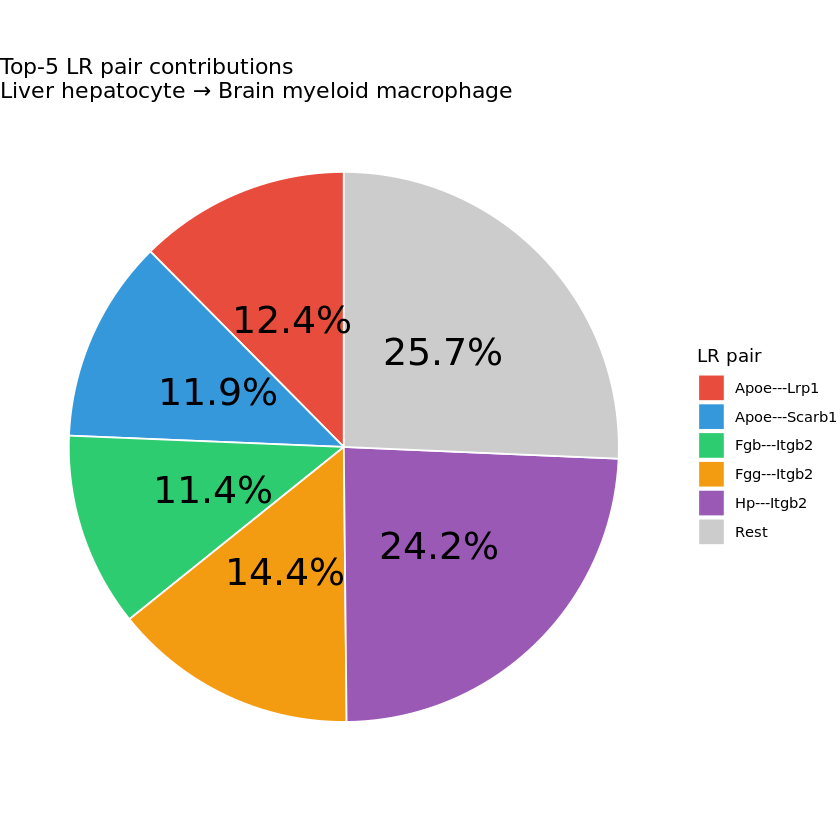

In [32]:
library(dplyr)
library(ggplot2)

x <- results_3m[[3]]$`Liver_hepatocyte---Brain_Myeloid_macrophage`

df <- tibble(
  pair  = names(x),
  value = as.numeric(x)
) %>%
  mutate(prop = value / sum(value)) %>%
  arrange(desc(prop))

df_top5 <- df %>%
  mutate(pair = ifelse(row_number() <= 5, pair, "Rest")) %>%
  group_by(pair) %>%
  summarise(prop = sum(prop), .groups = "drop") %>%
  mutate(perc_label = paste0(round(prop*100,1), "%"))  # percentage label


custom_colors <- c("#E74C3C", "#3498DB", "#2ECC71", "#F39C12", "#9B59B6", "grey80")

ggplot(df_top5, aes(x = "", y = prop, fill = pair)) +
  geom_bar(stat = "identity", width = 1, color = "white") +
  coord_polar("y") +
  geom_text(aes(label = perc_label),
            position = position_stack(vjust = 0.5), size = 8) +
  theme_void() +
  labs(
    title = "Top-5 LR pair contributions\nLiver hepatocyte → Brain myeloid macrophage",
    fill = "LR pair"
  ) +
  scale_fill_manual(values = custom_colors)


##### Aged

In [20]:
results_24m <- readRDS("/QRISdata/Q5058/IOC/Benchmark_results/CSOMap/brain_Liver_facs_24m.rds")

In [36]:
save_html(subset(results_24m[[1]],labels %in% c("Brain_Non-Myeloid_endothelial cell",
                                               "Liver_endothelial cell of hepatic sinusoid",
                                               "Brain_Myeloid_macrophage",
                                               "Liver_hepatocyte")),"facs_brain_Liver_24m")

In [8]:
df <- results_24m[[2]]$pvalue_tbl
df_IoC <- df %>%
  separate(organ, into = c("organ1", "organ2"), sep = "---") %>%
  filter(
    !grepl("Brain", organ1) |
    !grepl("Brain", organ2)
  ) %>%
    filter(
    !grepl("Liver", organ1) |
    !grepl("Liver", organ2)
  ) %>%
    filter(
        q.value<0.05
    )
df_IoC[order(df_IoC$q.value),]

,cluster_pair,p.value,q.value,organ1,organ2
,<chr>,<dbl>,<dbl>,<chr>,<chr>
18,"Liver_CD8-positive, alpha-beta T cell---Brain_Non-Myeloid_CD8-positive, alpha-beta T cell",0.000000e+00,0.000000e+00,Liver,Brain
20,"Liver_mature NK T cell---Brain_Non-Myeloid_CD8-positive, alpha-beta T cell",0.000000e+00,0.000000e+00,Liver,Brain
24,Liver_endothelial cell of hepatic sinusoid---Brain_Non-Myeloid_endothelial cell,1.712202e-283,5.307825e-282,Liver,Brain
23,"Liver_T cell---Brain_Non-Myeloid_CD8-positive, alpha-beta T cell",9.582351e-203,2.621055e-201,Liver,Brain
3,Liver_hepatocyte---Brain_Myeloid_macrophage,4.910074e-198,1.268436e-196,Liver,Brain_Myeloid
17,"Liver_CD4-positive, alpha-beta T cell---Brain_Non-Myeloid_CD8-positive, alpha-beta T cell",8.822266e-185,2.159134e-183,Liver,Brain
10,Liver_endothelial cell of hepatic sinusoid---Brain_Myeloid_microglial cell,1.824706e-177,4.242442e-176,Liver,Brain_Myeloid
22,"Liver_NK cell---Brain_Non-Myeloid_CD8-positive, alpha-beta T cell",6.811816e-174,1.508331e-172,Liver,Brain
9,"Liver_CD8-positive, alpha-beta T cell---Brain_Myeloid_microglial cell",7.251578e-91,1.248883e-89,Liver,Brain_Myeloid


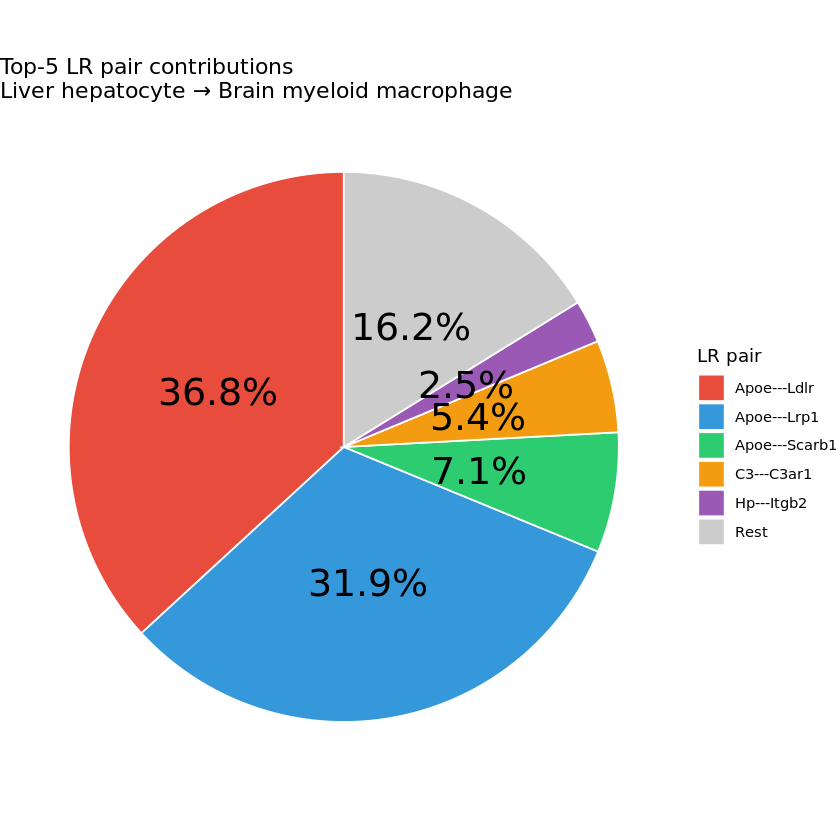

In [46]:
library(dplyr)
library(ggplot2)

x <- results_24m[[3]]$`Brain_Myeloid_macrophage---Liver_hepatocyte`

df <- tibble(
  pair  = names(x),
  value = as.numeric(x)
) %>%
  mutate(prop = value / sum(value)) %>%
  arrange(desc(prop))

df_top5 <- df %>%
  mutate(pair = ifelse(row_number() <= 5, pair, "Rest")) %>%
  group_by(pair) %>%
  summarise(prop = sum(prop), .groups = "drop") %>%
  mutate(perc_label = paste0(round(prop*100,1), "%"))  # percentage label


custom_colors <- c("#E74C3C", "#3498DB", "#2ECC71", "#F39C12", "#9B59B6", "grey80")

ggplot(df_top5, aes(x = "", y = prop, fill = pair)) +
  geom_bar(stat = "identity", width = 1, color = "white") +
  coord_polar("y") +
  geom_text(aes(label = perc_label),
            position = position_stack(vjust = 0.5), size = 8) +
  theme_void() +
  labs(
    title = "Top-5 LR pair contributions\nLiver hepatocyte → Brain myeloid macrophage",
    fill = "LR pair"
  ) +
  scale_fill_manual(values = custom_colors)
